In [ ]:
import os, time, warnings, zipfile, glob, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
warnings.filterwarnings("ignore")
np.random.seed(42)
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)

In [ ]:
# In Colab: choose bank_cleaned_csv__1_.zip (or bank_cleaned.csv) when prompted.
try:
    from google.colab import files
    up = files.upload()
except ImportError:
    up = {}          # running locally: put the file next to the notebook
for f in glob.glob("*.zip"):
    zipfile.ZipFile(f).extractall(".")
CSV = glob.glob("**/bank_cleaned.csv", recursive=True)[0]
df = pd.read_csv(CSV, index_col=0).reset_index(drop=True)   # first column is an old index -> dropped
print("Loaded:", CSV, df.shape)

Saving bank_cleaned.csv.zip to bank_cleaned.csv.zip
Loaded: bank_cleaned.csv (40841, 17)


In [ ]:
display(df.head())
print(df.dtypes, "\n\nMissing values:", int(df.isna().sum().sum()), "| duplicates:", int(df.duplicated().sum()))
print("\nTarget (response_binary):"); print(df.response_binary.value_counts().to_frame("n").assign(pct=lambda d: (100*d.n/len(df)).round(2)))
print("\nMonth order of first appearance (checks chronological ordering):", list(pd.unique(df.month)))

,age,job,marital,education,default,balance,housing,loan,day,month,duration,campaign,pdays,previous,poutcome,response,response_binary
0,58,management,married,tertiary,no,2143,yes,no,5,may,4.35,1,-1,0,unknown,no,0
1,44,technician,single,secondary,no,29,yes,no,5,may,2.52,1,-1,0,unknown,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,5,may,1.27,1,-1,0,unknown,no,0
3,35,management,married,tertiary,no,231,yes,no,5,may,2.32,1,-1,0,unknown,no,0
4,28,management,single,tertiary,no,447,yes,yes,5,may,3.62,1,-1,0,unknown,no,0


age                  int64
job                 object
marital             object
education           object
default             object
balance              int64
housing             object
loan                object
day                  int64
month               object
duration           float64
campaign             int64
pdays                int64
previous             int64
poutcome            object
response            object
response_binary      int64
dtype: object 

Missing values: 0 | duplicates: 0

Target (response_binary):
                     n    pct
response_binary              
0                36202  88.64
1                 4639  11.36

Month order of first appearance (checks chronological ordering): ['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb', 'mar', 'apr', 'sep']


In [ ]:
QUICK = False           # True = fast smoke test (small R, few updates)
EVAL_MODE = "time"      # "time"   = paper-faithful: oldest rows train, newest rows test (rows assumed chronological)
                        # "random" = rows shuffled first (NOT paper-faithful, but useful if the newest rows come from a different regime)
if EVAL_MODE == "random":
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

# ---- paper parameters -------------------------------------------------------
T1, T2, T3, T4 = 0.60, 0.65, 0.01, 0.60
K       = 10                                   # predictions per model update (paper)
L       = int(round(len(df) * 1293/52944))     # test length, same proportion as paper (~1000)
W       = int(round((len(df)-L) * 20000/51651))# window size, same proportion as paper (~15,400)
NR_FINAL = 7                                   # NN ensemble size (paper)
R       = 20 if not QUICK else 2               # holdout runs (paper R=20; reduce if too slow)
R_FS    = 4  if not QUICK else 1               # runs for feature-selection experiments (reduced for speed)
NR_FS   = 3  if not QUICK else 1               # NN ensemble size during feature selection (paper 7; reduced)
U_MAX   = None if not QUICK else 10            # limit rolling updates in QUICK mode
print(f"Train={len(df)-L}  Test(L)={L}  W={W}  K={K}  updates U={L//K}")

# ---- target + raw inputs (duration removed: unknown before the call) ---------
target = "response_binary"
raw = df.drop(columns=["response", "response_binary", "duration"])
cat_cols = [c for c in raw.columns if raw[c].dtype == object or str(raw[c].dtype).startswith(("str", "string"))]
for c in cat_cols: raw[c] = pd.Categorical(raw[c], categories=sorted(raw[c].unique()))   # fixed schema only (no stats)
num_cols = [c for c in raw.columns if c not in cat_cols]
y_all = df[target].values

def encode(r):
    return pd.get_dummies(r, columns=cat_cols, dtype=float)
X_all = encode(raw)
owner = {c: next((f for f in raw.columns if c == f or c.startswith(f + "_")), c) for c in X_all.columns}  # column -> original feature
def cols_of(feats): return [c for c in X_all.columns if owner[c] in feats]

n_train = len(df) - L
tr_idx, te_idx = np.arange(n_train), np.arange(n_train, len(df))
print("Encoded inputs:", X_all.shape[1], "| train positives %:", round(100*y_all[tr_idx].mean(),2), "| test positives %:", round(100*y_all[te_idx].mean(),2))

# ---- business "questions" (factors) adapted to the attributes that exist -------
factors = {
 "F1 Is client profile relevant?":            ["age", "job", "marital", "education"],
 "F2 Are financial status/assets relevant?":  ["default", "balance", "housing", "loan"],
 "F3 Are date/time conditions relevant?":     ["day", "month"],
 "F4 Is contact history relevant?":           ["campaign", "pdays", "previous", "poutcome"],
}

Train=39844  Test(L)=997  W=15428  K=10  updates U=99
Encoded inputs: 45 | train positives %: 10.35 | test positives %: 51.65


In [ ]:
_trap = getattr(np, "trapezoid", None) or np.trapz      # works on old and new NumPy
def alift(y, s):
    """Area under the cumulative LIFT curve (x = fraction contacted, y = fraction of responders captured)."""
    y = np.asarray(y); o = np.argsort(-np.asarray(s), kind="mergesort")
    cum = np.concatenate([[0], np.cumsum(y[o]) / y.sum()])
    return _trap(cum, np.linspace(0, 1, len(y) + 1))
assert abs(alift(np.array([1,0,1,0]*250), np.random.rand(1000)) - 0.5) < 0.05   # random baseline ~ 0.5

class NNEnsemble:
    """Paper NN: 1 hidden layer (H logistic nodes), logistic output, quasi-Newton training (L-BFGS ~ BFGS),
    100 epochs, ensemble of Nr nets averaged. H=0 -> logistic regression. Inputs standardised."""
    def __init__(self, H=6, Nr=7, max_iter=100, seed=0): self.H, self.Nr, self.max_iter, self.seed = H, Nr, max_iter, seed
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X); Xs = self.sc.transform(X)
        if self.H == 0: self.m = [LogisticRegression(max_iter=300).fit(Xs, y)]
        else: self.m = [MLPClassifier((self.H,), activation="logistic", solver="lbfgs", max_iter=self.max_iter,
                                      alpha=1e-3, random_state=self.seed+i).fit(Xs, y) for i in range(self.Nr)]
        return self
    def predict_proba(self, X):
        Xs = self.sc.transform(X); return np.mean([m.predict_proba(Xs)[:, 1] for m in self.m], axis=0)

class SVMPlatt:
    """Gaussian-kernel SVM, C=3, standardised inputs; probability via Platt sigmoid on decision values."""
    def __init__(self, gamma="scale", C=3): self.gamma, self.C = gamma, C
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X); Xs = self.sc.transform(X)
        self.svm = SVC(kernel="rbf", gamma=self.gamma, C=self.C).fit(Xs, y)
        i = np.random.RandomState(0).choice(len(Xs), min(4000, len(Xs)), replace=False)
        self.pl = LogisticRegression().fit(self.svm.decision_function(Xs[i]).reshape(-1,1), y[i]); return self
    def predict_proba(self, X): return self.pl.predict_proba(self.svm.decision_function(self.sc.transform(X)).reshape(-1,1))[:, 1]

class Std:
    def __init__(self, m): self.m = m
    def fit(self, X, y): self.sc = StandardScaler().fit(X); self.m.fit(self.sc.transform(X), y); return self
    def predict_proba(self, X): return self.m.predict_proba(self.sc.transform(X))[:, 1]

def make_model(name, H=6, Nr=NR_FINAL, gamma="scale"):
    return {"LR":  lambda: Std(LogisticRegression(max_iter=300)),
            "DT":  lambda: Std(DecisionTreeClassifier(ccp_alpha=5e-4, min_samples_split=20, random_state=0)),  # CART, pruned (rpart-like)
            "SVM": lambda: SVMPlatt(gamma=gamma),
            "NN":  lambda: NNEnsemble(H=H, Nr=Nr)}[name]()

def holdout_scores(name, feats, runs, idx=tr_idx, **kw):
    """Paper holdout: random 2/3 train / 1/3 validation inside the TRAINING data, repeated `runs` times."""
    cols = cols_of(feats); X = X_all.loc[idx, cols].values; y = y_all[idx]; res = []
    for r in range(runs):
        rs = np.random.RandomState(100 + r); p = rs.permutation(len(idx)); a, b = p[:2*len(p)//3], p[2*len(p)//3:]
        kw2 = dict(kw)
        if name == "NN" and "H" not in kw2: kw2["H"] = max(1, round(len(cols)/2))      # heuristic H = round(M/2)
        s = make_model(name, **kw2).fit(X[a], y[a]).predict_proba(X[b])
        res.append((roc_auc_score(y[b], s), alift(y[b], s)))
    return np.array(res)          # shape (runs, 2): AUC, ALIFT

In [ ]:
def perm_importance(feats, runs=2):
    """Importance (%) of each ORIGINAL feature via permutation on the validation fold (AUC drop)."""
    cols = cols_of(feats); X = X_all.loc[tr_idx, cols].values; y = y_all[tr_idx]; imp = {f: 0.0 for f in feats}
    for r in range(runs):
        rs = np.random.RandomState(7 + r); p = rs.permutation(len(tr_idx)); a, b = p[:2*len(p)//3], p[2*len(p)//3:]
        m = make_model("NN", H=max(1, round(len(cols)/2)), Nr=NR_FS).fit(X[a], y[a]); base = roc_auc_score(y[b], m.predict_proba(X[b]))
        for f in feats:
            Xp = X[b].copy(); ci = [i for i, c in enumerate(cols) if owner[c] == f]
            Xp[:, ci] = Xp[rs.permutation(len(b))][:, ci]
            imp[f] += max(base - roc_auc_score(y[b], m.predict_proba(Xp)), 0)
    tot = sum(imp.values()) or 1; return {f: v / tot for f, v in imp.items()}

t0 = time.time(); selected, confirmed, fs_log = {}, [], []
for q, feats in factors.items():
    aucq  = holdout_scores("NN", feats, R_FS, Nr=NR_FS)[:, 0].mean()
    indiv = {f: holdout_scores("NN", [f], R_FS, Nr=NR_FS)[:, 0].mean() for f in feats}
    m_f = max(indiv, key=indiv.get); ok = indiv[m_f] > T1 and aucq > T2
    if ok:
        if indiv[m_f] > aucq or aucq - indiv[m_f] < T3: keep = [m_f]
        else:
            imp = perm_importance(feats); keep, cum = [], 0
            for f, v in sorted(imp.items(), key=lambda kv: -kv[1]):
                keep.append(f); cum += v
                if cum >= T4: break
        selected[q] = keep; confirmed.append(q)
    fs_log.append(dict(factor=q, AUC_all=round(aucq,3), best_single=m_f, AUC_best_single=round(indiv[m_f],3), confirmed=ok,
                       kept=selected.get(q, [])))
fs1 = pd.DataFrame(fs_log); display(fs1)
n_before = sum(len(v) for v in factors.values()); n_after = sum(len(v) for v in selected.values())
print(f"Phase 1: {n_before} features -> {n_after} features ({len(confirmed)}/{len(factors)} factors confirmed)  [{time.time()-t0:.0f}s]")

,factor,AUC_all,best_single,AUC_best_single,confirmed,kept
0,F1 Is client profile relevant?,0.634,job,0.593,False,[]
1,F2 Are financial status/assets relevant?,0.646,housing,0.601,False,[]
2,F3 Are date/time conditions relevant?,0.708,month,0.649,True,[month]
3,F4 Is contact history relevant?,0.631,poutcome,0.585,False,[]


Phase 1: 14 features -> 1 features (1/4 factors confirmed)  [120s]


In [ ]:
# Phase 2 – forward selection over confirmed factors
cur, prev_auc, fwd = [], 0.0, []
for q in confirmed:
    trial = cur + selected[q]
    auc = holdout_scores("NN", trial, R_FS, Nr=NR_FS)[:, 0].mean()
    keep = auc > prev_auc; fwd.append(dict(factor_added=q, features=selected[q], AUC=round(auc,4), kept=keep))
    if keep: cur, prev_auc = trial, auc
display(pd.DataFrame(fwd))
FINAL_FEATS = cur if cur else list(raw.columns)
print("FINAL FEATURES:", FINAL_FEATS, "| encoded inputs:", len(cols_of(FINAL_FEATS)))

,factor_added,features,AUC,kept
0,F3 Are date/time conditions relevant?,[month],0.649,True


FINAL FEATURES: ['month'] | encoded inputs: 12


In [ ]:
FC = cols_of(FINAL_FEATS); Xtr, ytr = X_all.loc[tr_idx, FC].values, y_all[tr_idx]
sub = np.random.RandomState(1).choice(len(tr_idx), 5000, replace=False); p = np.random.RandomState(2).permutation(5000)
a, b = sub[p[:3333]], sub[p[3333:]]
gridH = {H: roc_auc_score(ytr[b], make_model("NN", H=H, Nr=NR_FS).fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])) for H in [0,2,6,8,10,12]}
gridG = {k: roc_auc_score(ytr[b], make_model("SVM", gamma=2.0**k).fit(Xtr[a], ytr[a]).predict_proba(Xtr[b])) for k in [-15,-11.4,-7.8,-4.2,-0.6,3]}
print("NN grid (H -> AUC):", {k: round(v,4) for k, v in gridH.items()})
print("SVM grid (log2 gamma -> AUC):", {k: round(v,4) for k, v in gridG.items()})
BEST_H = max(gridH, key=gridH.get); BEST_G = 2.0 ** max(gridG, key=gridG.get)
print("Selected H =", BEST_H, "| gamma =", BEST_G)

NN grid (H -> AUC): {0: np.float64(0.6363), 2: np.float64(0.6364), 6: np.float64(0.6365), 8: np.float64(0.6364), 10: np.float64(0.6364), 12: np.float64(0.6364)}
SVM grid (log2 gamma -> AUC): {-15: np.float64(0.3898), -11.4: np.float64(0.4587), -7.8: np.float64(0.4266), -4.2: np.float64(0.5088), -0.6: np.float64(0.4619), 3: np.float64(0.5815)}
Selected H = 6 | gamma = 8.0


In [ ]:
t0 = time.time(); runs = {}
for name, kw in [("LR", {}), ("DT", {}), ("SVM", dict(gamma=BEST_G)), ("NN", dict(H=BEST_H, Nr=NR_FS))]:
    runs[name] = holdout_scores(name, FINAL_FEATS, R, **kw); print(name, "done", f"{time.time()-t0:.0f}s")
tab3 = pd.DataFrame({n: {"AUC": v[:,0].mean(), "ALIFT": v[:,1].mean()} for n, v in runs.items()}).round(3)
display(tab3)
for n in ["LR", "DT", "SVM"]:
    p = mannwhitneyu(runs["NN"][:,0], runs[n][:,0]).pvalue
    print(f"NN vs {n}: AUC diff = {100*(runs['NN'][:,0].mean()-runs[n][:,0].mean()):+.1f} pp, Mann-Whitney p = {p:.4f}")
tab3.to_csv(f"{OUT}/table3_modeling_phase.csv")

LR done 1s
DT done 2s
SVM done 323s
NN done 354s


,LR,DT,SVM,NN
AUC,0.647,0.623,0.596,0.648
ALIFT,0.632,0.611,0.586,0.632


NN vs LR: AUC diff = +0.0 pp, Mann-Whitney p = 0.9676
NN vs DT: AUC diff = +2.4 pp, Mann-Whitney p = 0.0000
NN vs SVM: AUC diff = +5.2 pp, Mann-Whitney p = 0.0000


In [ ]:
t0 = time.time(); allf = list(raw.columns)
def timed(fn): s = time.time(); r = fn(); return r, time.time() - s
# (a) no selection
(auc_all), t_all = timed(lambda: holdout_scores("NN", allf, R_FS, Nr=NR_FS)[:,0].mean())
# (b) standard forward selection over individual features
def forward():
    chosen, best = [], 0
    while True:
        cand = {f: holdout_scores("NN", chosen+[f], 1, Nr=1)[:,0].mean() for f in allf if f not in chosen}   # 1 run, 1 net: speed
        if not cand: break
        f = max(cand, key=cand.get)
        if cand[f] <= best: break
        chosen.append(f); best = cand[f]
    return chosen, best
(fw, auc_fw), t_fw = timed(forward)
tab4 = pd.DataFrame([["no selection", len(allf), round(t_all), round(auc_all,3)],
                     ["forward selection", len(fw), round(t_fw), round(auc_fw,3)],
                     ["proposed (factor-based)", len(FINAL_FEATS), "see Cell 6", round(prev_auc,3)]],
                    columns=["Method", "#Original features", "Time (s)", "AUC"])
display(tab4); tab4.to_csv(f"{OUT}/table4_feature_selection.csv", index=False)

,Method,#Original features,Time (s),AUC
0,no selection,14,109,0.740
1,forward selection,7,211,0.746
2,proposed (factor-based),1,see Cell 6,0.649


In [ ]:
def rolling(name, feats, W=W, K=K, **kw):
    cols = cols_of(feats); X, y = X_all[cols].values, y_all
    starts = list(range(n_train, len(df), K)); starts = starts[:U_MAX] if U_MAX else starts
    P, Y = [], []
    for s in starts:
        e = min(s + K, len(df)); m = make_model(name, **kw).fit(X[s-W:s], y[s-W:s])
        P.append(m.predict_proba(X[s:e])); Y.append(y[s:e])
    return np.concatenate(Y), np.concatenate(P)

t0 = time.time(); roll = {}
for name, kw in [("LR", {}), ("DT", {}), ("SVM", dict(gamma=BEST_G)), ("NN", dict(H=BEST_H, Nr=NR_FINAL))]:
    roll[name] = rolling(name, FINAL_FEATS, **kw); print(name, "done", f"{time.time()-t0:.0f}s")
tab5 = pd.DataFrame({n: {"AUC": roc_auc_score(*roll[n]), "ALIFT": alift(*roll[n])} for n in roll}).round(3)
display(tab5); tab5.to_csv(f"{OUT}/table5_rolling_window.csv")

LR done 2s
DT done 3s
SVM done 655s
NN done 836s


,LR,DT,SVM,NN
AUC,0.476,0.451,0.459,0.477
ALIFT,0.489,0.477,0.480,0.489


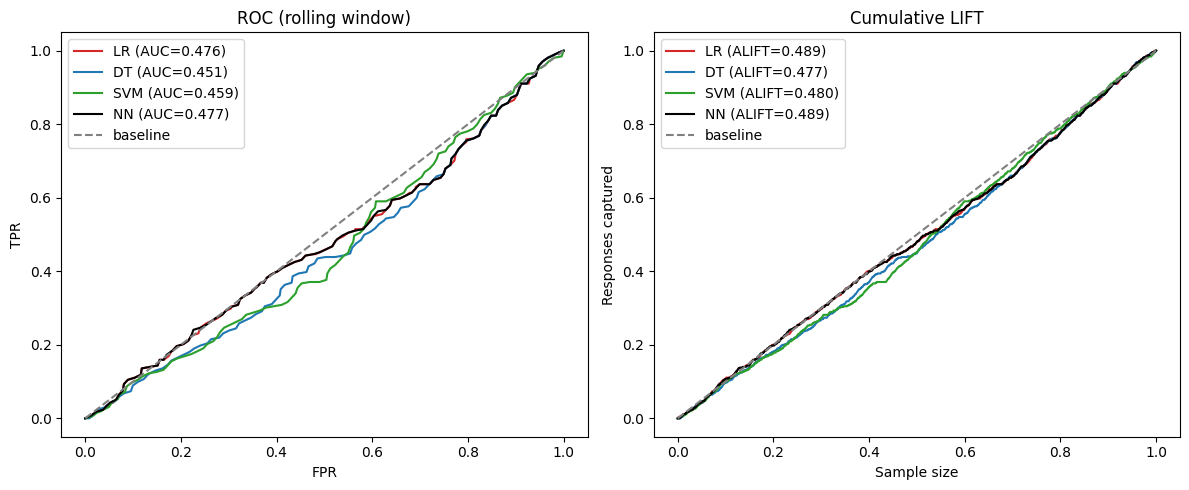

NN confusion matrix, threshold D=0.5 (rows=target failure/success, cols=predicted):
 [[482   0]
 [515   0]] 
%:
 [[48.3  0. ]
 [51.7  0. ]]


,10%,20%,30%,40%,50%,60%,70%
model,,,,,,,
LR,10.7,20.0,29.7,40.0,48.0,56.9,65.6
DT,9.7,18.1,26.8,36.9,44.9,55.5,66.0
SVM,9.9,17.7,27.2,35.5,45.0,59.0,68.0
NN,10.7,19.8,29.9,39.8,48.0,57.1,65.6


NN: contacting the top 50% captures 48.0 % of subscribers (random = 50%). Paper: ~79%.


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5)); cols_ = dict(NN="k", DT="tab:blue", SVM="tab:green", LR="tab:red")
for n, (yy, ss) in roll.items():
    f, t, _ = roc_curve(yy, ss); ax[0].plot(f, t, color=cols_[n], label=f"{n} (AUC={roc_auc_score(yy, ss):.3f})")
    o = np.argsort(-ss); ax[1].plot(np.linspace(0,1,len(yy)+1), np.concatenate([[0], np.cumsum(yy[o])/yy.sum()]), color=cols_[n], label=f"{n} (ALIFT={alift(yy, ss):.3f})")
ax[0].plot([0,1],[0,1],"--",c="gray",label="baseline"); ax[1].plot([0,1],[0,1],"--",c="gray",label="baseline")
ax[0].set(xlabel="FPR", ylabel="TPR", title="ROC (rolling window)"); ax[1].set(xlabel="Sample size", ylabel="Responses captured", title="Cumulative LIFT")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.savefig(f"{OUT}/fig_roc_lift.png", dpi=150); plt.show()

yy, ss = roll["NN"]; cm = confusion_matrix(yy, ss > 0.5)
print("NN confusion matrix, threshold D=0.5 (rows=target failure/success, cols=predicted):\n", cm, "\n%:\n", (100*cm/cm.sum()).round(1))
rows = []
for n, (yy_, ss_) in roll.items():
    o = np.argsort(-ss_); cum = np.cumsum(yy_[o]) / yy_.sum()
    rows.append({"model": n, **{f"{int(q*100)}%": round(100*cum[int(q*len(yy_))-1], 1) for q in [.1, .2, .3, .4, .5, .6, .7]}})
lift_tab = pd.DataFrame(rows).set_index("model"); display(lift_tab); lift_tab.to_csv(f"{OUT}/lift_table.csv")
print("NN: contacting the top 50% captures", lift_tab.loc["NN","50%"], "% of subscribers (random = 50%). Paper: ~79%.")

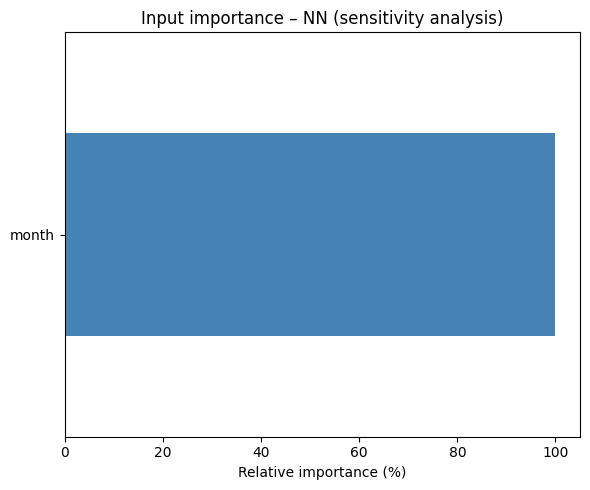

Top-5: ['month']


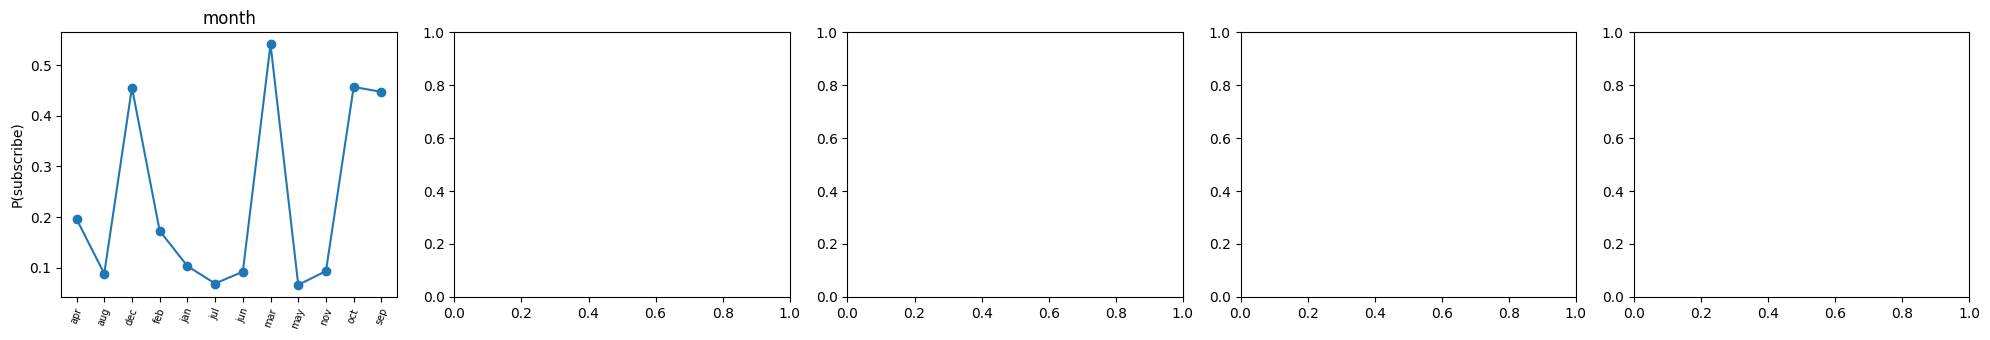

In [ ]:
# NN fitted on ALL training data (paper) with the final inputs
final_nn = make_model("NN", H=BEST_H, Nr=NR_FINAL).fit(X_all.loc[tr_idx, FC].values, y_all[tr_idx])
S = raw.iloc[tr_idx].sample(1500, random_state=0)           # sample of real contacts
def levels(f, n=7):
    if f in cat_cols: return list(raw[f].cat.categories)
    return list(np.unique(np.quantile(raw[f].iloc[tr_idx], np.linspace(0.02, 0.98, n)).round(2)))
def respond(f, v):
    d = S.copy()
    d[f] = pd.Categorical([v]*len(d), categories=raw[f].cat.categories) if f in cat_cols else v
    return final_nn.predict_proba(encode(d)[FC].values).mean()
vec = {f: (levels(f), [respond(f, v) for v in levels(f)]) for f in FINAL_FEATS}
imp = pd.Series({f: np.std(r) for f, (lv, r) in vec.items()}); imp = (100 * imp / imp.sum()).sort_values()
plt.figure(figsize=(6, 5)); imp.plot.barh(color="steelblue"); plt.xlabel("Relative importance (%)"); plt.title("Input importance – NN (sensitivity analysis)")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_importance.png", dpi=150); plt.show()
top = imp.sort_values(ascending=False).index[:5]; print("Top-5:", list(top))
fig, axs = plt.subplots(1, 5, figsize=(20, 3.5))
for a_, f in zip(axs, top):
    lv, r = vec[f]; xs = range(len(lv)) if f in cat_cols else lv
    a_.plot(xs, r, "o-"); a_.set_title(f); a_.set_ylabel("P(subscribe)")
    if f in cat_cols: a_.set_xticks(range(len(lv))); a_.set_xticklabels(lv, rotation=70, fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_vec_curves.png", dpi=150); plt.show()

Mean absolute error of DT vs NN responses: 0.0104 (paper: 0.03)


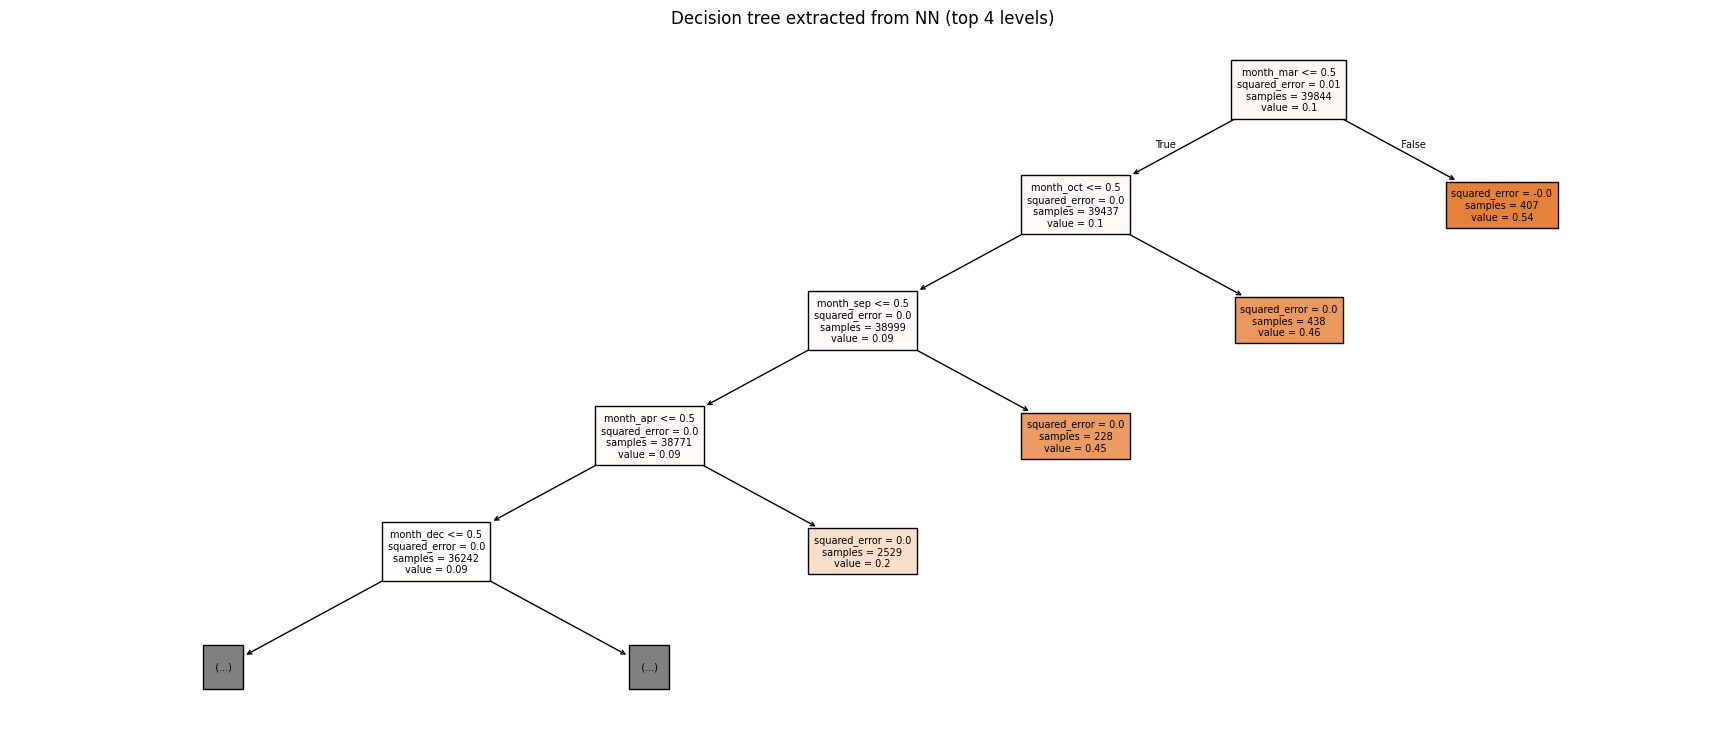

|--- month_mar <= 0.50
|   |--- month_oct <= 0.50
|   |   |--- month_sep <= 0.50
|   |   |   |--- month_apr <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- month_apr >  0.50
|   |   |   |   |--- value: [0.20]
|   |   |--- month_sep >  0.50
|   |   |   |--- value: [0.45]
|   |--- month_oct >  0.50
|   |   |--- value: [0.46]
|--- month_mar >  0.50
|   |--- value: [0.54]



In [ ]:
Xs_tr = X_all.loc[tr_idx, FC]; nn_out = final_nn.predict_proba(Xs_tr.values)
dt = DecisionTreeRegressor(ccp_alpha=1e-4, min_samples_leaf=50, random_state=0).fit(Xs_tr, nn_out)       # learns the NN's responses
print("Mean absolute error of DT vs NN responses:", round(np.mean(np.abs(dt.predict(Xs_tr) - nn_out)), 4), "(paper: 0.03)")
plt.figure(figsize=(22, 9)); plot_tree(dt, max_depth=4, feature_names=FC, filled=True, fontsize=7, precision=2)
plt.title("Decision tree extracted from NN (top 4 levels)"); plt.savefig(f"{OUT}/fig_extracted_tree.png", dpi=130); plt.show()
print(export_text(dt, feature_names=FC, max_depth=3))

In [ ]:
paper = {"Table 3 (modeling) AUC": dict(LR=0.900, DT=0.833, SVM=0.891, NN=0.929),
         "Table 3 (modeling) ALIFT": dict(LR=0.849, DT=0.756, SVM=0.844, NN=0.878),
         "Table 5 (rolling) AUC": dict(LR=0.715, DT=0.757, SVM=0.767, NN=0.794),
         "Table 5 (rolling) ALIFT": dict(LR=0.626, DT=0.651, SVM=0.656, NN=0.672)}
mine = {"Table 3 (modeling) AUC": tab3.loc["AUC"], "Table 3 (modeling) ALIFT": tab3.loc["ALIFT"],
        "Table 5 (rolling) AUC": tab5.loc["AUC"], "Table 5 (rolling) ALIFT": tab5.loc["ALIFT"]}
rows = [dict(Experiment=k, Model=m, Paper=v, Yours=round(float(mine[k][m]), 3), Difference=round(float(mine[k][m]) - v, 3))
        for k, d in paper.items() for m, v in d.items()]
cmp_ = pd.DataFrame(rows); display(cmp_); cmp_.to_csv(f"{OUT}/comparison_with_paper.csv", index=False)
print("Best model, modeling phase :", tab3.loc["AUC"].idxmax(), "(paper: NN)")
print("Best model, rolling window :", tab5.loc["AUC"].idxmax(), "(paper: NN)")
print("Ranking (rolling AUC):", " > ".join(tab5.loc["AUC"].sort_values(ascending=False).index), "| paper: NN > SVM > DT > LR")
print("NN top-50% capture:", lift_tab.loc["NN","50%"], "% vs paper 79%")

,Experiment,Model,Paper,Yours,Difference
0,Table 3 (modeling) AUC,LR,0.900,0.647,-0.253
1,Table 3 (modeling) AUC,DT,0.833,0.623,-0.210
2,Table 3 (modeling) AUC,SVM,0.891,0.596,-0.295
3,Table 3 (modeling) AUC,NN,0.929,0.648,-0.281
4,Table 3 (modeling) ALIFT,LR,0.849,0.632,-0.217
5,Table 3 (modeling) ALIFT,DT,0.756,0.611,-0.145
6,Table 3 (modeling) ALIFT,SVM,0.844,0.586,-0.258
7,Table 3 (modeling) ALIFT,NN,0.878,0.632,-0.246
8,Table 5 (rolling) AUC,LR,0.715,0.476,-0.239
9,Table 5 (rolling) AUC,DT,0.757,0.451,-0.306


Best model, modeling phase : NN (paper: NN)
Best model, rolling window : NN (paper: NN)
Ranking (rolling AUC): NN > LR > SVM > DT | paper: NN > SVM > DT > LR
NN top-50% capture: 48.0 % vs paper 79%


In [ ]:
joblib.dump(dict(final_nn=final_nn, features=FINAL_FEATS, encoded_columns=FC, H=BEST_H, gamma=BEST_G), f"{OUT}/final_nn_model.joblib")
pd.DataFrame({n: {"AUC": roc_auc_score(*roll[n]), "ALIFT": alift(*roll[n])} for n in roll}).to_csv(f"{OUT}/final_metrics.csv")
imp.sort_values(ascending=False).to_csv(f"{OUT}/sensitivity_importance.csv")
import shutil; shutil.make_archive("replication_outputs", "zip", OUT)
print(sorted(os.listdir(OUT)))
try:
    from google.colab import files; files.download("replication_outputs.zip")   # downloads everything as one zip
except ImportError: print("Not on Colab: see replication_outputs.zip")

['comparison_with_paper.csv', 'fig_extracted_tree.png', 'fig_importance.png', 'fig_roc_lift.png', 'fig_vec_curves.png', 'final_metrics.csv', 'final_nn_model.joblib', 'lift_table.csv', 'sensitivity_importance.csv', 'table3_modeling_phase.csv', 'table4_feature_selection.csv', 'table5_rolling_window.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>